In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import IterableDataset, DataLoader
import cudf
import cupy as cp
import numpy as np
import os
import fsspec
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score
import dask_cudf
from dask.distributed import Client, progress
from dask_cuda import LocalCUDACluster
from torch.cuda.amp import autocast, GradScaler
import dask.dataframe as dd
import dask.array as da
from torch.utils.data import DataLoader, Dataset
import pandas as pd
import pyarrow.parquet as pq
import torch.optim as optim
import ast
import torch.nn.functional as F
import dask.dataframe as dd
from tqdm.auto import tqdm # For progress bar


In [3]:
#torch.set_float32_matmul_precision('high')
#torch.backends.cuda.matmul.fp32_precision = 'ieee'


# 1. New API for TF32 control (removes the deprecation warning)
torch.backends.cuda.matmul.fp32_precision = 'tf32' 

# 2. Enables high precision (TF32) for better Inductor/GPU performance 
# (removes the performance warning)
torch.set_float32_matmul_precision('high')



/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/torch/__init__.py:1624: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


In [4]:
#import dask
#import dask_cuda
#import cudf
#import cupy
#from dask.distributed import Client, LocalCluster
#from dask_cuda import LocalCUDACluster
#import dask_cudf
#import os

# --- Configuration for Resource Usage ---
# Get total memory from nvidia-smi output (49140 MiB for RTX A6000)
# Convert MiB to Bytes: 49140 * 1024 * 1024 = 51520630784 Bytes
TOTAL_GPU_MEMORY_BYTES = 97887 * 1024 * 1024 

# Desired usage percentage
GPU_MEMORY_PERCENTAGE_TO_USE = 0.70 # 70%

# Calculate the memory limit for each worker
# LocalCUDACluster by default launches one worker per available GPU.
# So, if you have one A6000, one worker will use 70% of its memory.
DEVICE_MEMORY_LIMIT = int(TOTAL_GPU_MEMORY_BYTES * GPU_MEMORY_PERCENTAGE_TO_USE)

# You can optionally specify which GPUs to use if you have multiple
# and want to restrict to certain ones.
# For a single A6000, this is often not necessary unless you have other processes.
# CUDA_VISIBLE_DEVICES = "0" # Use only GPU 0

# --- Dask Cluster Setup ---
print(f"Setting device_memory_limit per worker to: {DEVICE_MEMORY_LIMIT / (1024**3):.2f} GB ({GPU_MEMORY_PERCENTAGE_TO_USE*100:.0f}% of total GPU memory)")

# 1. Start a Local Dask Cluster with GPU resources
# We pass the calculated device_memory_limit here.
# n_workers can be specified if you have multiple GPUs and want to use a subset.
# threads_per_worker is generally 1 for Dask-CUDA with cuDF/CuPy for best performance
# due to how CUDA streams and contexts are managed, especially if using RMM pools.
cluster = LocalCUDACluster(
    device_memory_limit=DEVICE_MEMORY_LIMIT,
    # Crucial for large workloads and preventing OOM:
    enable_cudf_spill=True, # Enable cuDF's native spilling to host if GPU memory is exhausted

    # Optional UCX for performance (requires ucx-py installed)
    protocol="ucx",
    enable_tcp_over_ucx=True,

    # threads_per_worker is generally 1 for CUDA workloads with cuDF/CuPy
    threads_per_worker=1,
)
client = Client(cluster)

print("\nDask Dashboard Link:", client.dashboard_link)
print("------------------------------------------")
print("Dask Client Info:")
print(client)
print("------------------------------------------")


Setting device_memory_limit per worker to: 66.91 GB (70% of total GPU memory)

Dask Dashboard Link: http://127.0.0.1:8787/status
------------------------------------------
Dask Client Info:
<Client: 'ucx://127.0.0.1:41081' processes=1 threads=1, memory=0.98 TiB>
------------------------------------------


In [5]:
import random
def set_seed(seed=42):
  np.random.seed(seed) 
  random.seed(seed)
set_seed()
try:
    torch.multiprocessing.set_start_method('spawn', force=True)
    print("Multiprocessing start method set to 'spawn'.")
except RuntimeError:
    print("Multiprocessing start method is already set.")

Multiprocessing start method set to 'spawn'.


In [6]:
PATH_RESNET_species = f"../cnn_kraken_species/checkpoints/best_resnet_classifier__fast_phase4.pt" 
PATH_RESNET_species_finetuned = f"../cnn_kraken/checkpoint_finetune_resnet/finetune_noise_14.pt"
PATH_CONVNEXT_zero_species = f"../cnn_kraken/checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt" 
PATH_CONVNEXT_transfer_species =f"../cnn_kraken/checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"
PATH_CONVNEXT_fine_species =  f"../cnn_kraken/checkpoint_transfer_species_conv/finetune_noise_7.pt"


In [7]:
mapping_csv_path_species = f"../dataset_kraken/species_name_ids.csv"

In [8]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 13683
MAX_SEQUENCE_LENGTH = 512
NUM_FEATURES = 4
BATCH_SIZE = 1024 
fs = fsspec.filesystem('file')
test_file_paths_species = fs.glob(os.path.join(f"./processed_kraken_species_splited_parquet/test", '*.parquet'))
NUCLEOTIDES = ['A', 'C', 'G', 'T']
PADDED_COLUMN = 'sequence_padded'
LABEL_COLUMN = 'label'




In [9]:
models = [
    {
        "model_name":"ConvNext finetuned",
        "path":PATH_CONVNEXT_fine_species,
        "type":"CONVNEXT_FINE"
        
    },
    {
        "model_name":"ConvNext from scratch",
        "path":PATH_CONVNEXT_zero_species,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ConvNext transfer from genus",
        "path":PATH_CONVNEXT_transfer_species,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ResNet50",
        "path":PATH_RESNET_species,
        "type":"RESNET"
    },
    {
        "model_name":"ResNet50_finetuned",
        "path":PATH_RESNET_species_finetuned,
        "type":"RESNET_FINE"
    },
]

In [10]:
def load_model(model_dict):
    # 1. Instanciação do Modelo Base
    if "CONVNEXT" in model_dict["type"]:
        dropout = 0.7 if model_dict["type"] == "CONVNEXT_FINE" else 0.5
        model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES, debug=False, dropout_rate=dropout)
    elif "RESNET" in model_dict["type"]:
        model = resnet50_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES, debug=False, dropout_rate=0.5)
    else:
        raise ValueError(f"Tipo de modelo desconhecido: {model_dict['type']}")

    # 2. Carregamento dos Pesos no modelo 'bruto'
    # Usar map_location garante que os pesos caiam no lugar certo desde o início
    try:
        print(f"Carregando pesos de: {model_dict['path']}")
        checkpoint = torch.load(model_dict["path"], map_location=DEVICE)
        
        # Extrai o dicionário de estados (suporta formatos simples ou com metadados de treino)
        state_dict = checkpoint["model_state_dict"] if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint else checkpoint
        
        # Limpa o prefixo '_orig_mod.' caso o checkpoint tenha sido salvo de um modelo já compilado
        new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
        
        model.load_state_dict(new_state_dict)
        print(f"Sucesso! Pesos carregados para {model_dict['model_name']}.")
    except Exception as e:
        print(f"ATENÇÃO: Falha ao carregar checkpoint: {e}")
        print("O modelo seguirá com inicialização aleatória.")

    # 3. Preparação para Inferência
    model.to(DEVICE)
    model.eval() # Essencial para congelar BatchNorm e Dropout antes da compilação

    # 4. Compilação (O ÚLTIMO PASSO)
    # Compilar apenas após o modelo estar com os pesos finais e no device correto
    print(f"Compilando modelo {model_dict['model_name']}...")
    model = torch.compile(model)
    
    return model

In [11]:
import sys
import os

# 1. Pega o diretório atual
current_dir = os.getcwd()

# 2. Pega o diretório pai (um nível acima)
parent_dir = os.path.dirname(current_dir)

# 3. Adiciona o pai ao caminho de busca do Python
sys.path.append(parent_dir)
# --- DEBUG (Opcional) ---
# Verifica se a pasta cnn_kraken realmente existe no pai
path_to_check = os.path.join(parent_dir, 'cnn_kraken')
if os.path.exists(path_to_check):
    print(f"✅ Pasta 'cnn_kraken' encontrada em: {path_to_check}")
else:
    print(f"❌ AVISO: Não encontrei 'cnn_kraken' em {parent_dir}. Verifique o caminho.")
    
from cnn_kraken.utils.analize_funcs import *
from cnn_kraken.utils.models import *
from cnn_kraken.utils.dna_dataset_2 import DaskCuDFIntegerDataset, ParquetCPUDataset
import fsspec

✅ Pasta 'cnn_kraken' encontrada em: /home/mlima/workspace/cnn_kraken


In [12]:
base_dir = f"./processed_ncbi_splited_parquet"
test_path = os.path.join(base_dir, 'test')

test_dataset = dd.read_parquet(test_path, blocksize="100MB")
test_dataset.head()

,species_id,genus_id,origin_len,read_len,sequence
41844,256,32,4735,3399,TTGATGTCATTGCACTGACTTCAAGTCTGCACGTTCCTGTACAGAA...
10992,87,2606,1088,1027,TCCCTCGTGAAAGTGTGTCCAGCTCGGGAACCAAACGCGGTAACCC...
16207,114,9,3634,1674,GCTAGCTACTTACGTAGAATGCTTGCAGATTTACCTGAAGGCACAG...
37361,223,31,7350,1538,GGAAGTTAGAAGGAAGGATGGGGGAATTTTCGATCCTGAAGCATAT...
41210,252,32,5175,3945,ATGAGGAGACCGCGCCTGTCGTCAGGTGCGTTATTAATGGTCGGAT...


In [13]:
# Configurações
WINDOW_SIZE = 512
STRIDE = 256  # 256 = 50% de overlap (melhora a precisão), 512 = sem overlap (mais rápido)
BATCH_SIZE_INFERENCE = 2048 # Quantas janelas processar de uma vez na GPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Mapeamento (O mesmo usado no treino)
DNA_MAP = {'A': 0, 'C': 1, 'G': 2, 'T': 3}

def text_to_tensor(seq_str, window_size, stride):
    """
    Fatia a sequência em janelas e retorna índices INTEIROS.
    Retorna: Tensor [N_windows, window_size] (dtype=torch.long)
    """
    seq_len = len(seq_str)
    windows = []
    
    # Gera as janelas
    for start in range(0, seq_len - window_size + 1, stride):
        window_str = seq_str[start : start + window_size]
        
        # Converte para índices (0, 1, 2, 3, 4)
        indices = [DNA_MAP.get(base, 4) for base in window_str]
        windows.append(indices)
    
    if not windows:
        return None

    # RETORNA APENAS INTEIROS (Rank 2)
    # Shape: [N_windows, 512]
    # O modelo vai receber isso e transformar em [N, 4, 512] internamente
    return torch.tensor(windows, dtype=torch.long)

def inject_sequencing_noise(tensor, rate=0.05):
    """Simula erros de sequenciamento (ex: 5%) diretamente no tensor."""
    mask = torch.rand(tensor.shape, device=tensor.device) < rate
    noise = torch.randint(0, 4, tensor.shape, device=tensor.device)
    return torch.where(mask, noise, tensor)

In [14]:
model = load_model(models[-1])

Carregando pesos de: ../cnn_kraken/checkpoint_finetune_resnet/finetune_noise_14.pt
Sucesso! Pesos carregados para ResNet50_finetuned.
Compilando modelo ResNet50_finetuned...


In [15]:
import torch
import torch.nn as nn
import numpy as np
from collections import Counter

def get_consensus_motif(weights_array, bases=['A', 'C', 'G', 'T'], use_abs=True):
    """
    Converte um array de pesos de filtro (4, K) em uma string de motivo de consenso.
    
    Args:
        weights_array: Pesos de um único filtro.
        bases: Lista de bases na ordem do One-Hot Encoding.
        use_abs: Se True, considera a maior magnitude (útil para filtros gerais).
                 Se False, considera apenas o maior peso positivo (ideal para ReLU).
    """
    # Transpõe para (K, 4) para iterar sobre as posições do kernel
    weights_transposed = weights_array.transpose()
    consensus_motif = ""
    
    for position_weights in weights_transposed:
        if use_abs:
            # Captura a base com maior influência (positiva ou negativa)
            max_idx = np.argmax(np.abs(position_weights))
        else:
            # Captura apenas a base que mais ativa o neurônio
            max_idx = np.argmax(position_weights)
            
        consensus_motif += bases[max_idx]
        
    return consensus_motif

def extract_motifs(model, bases=['A', 'C', 'G', 'T'], use_abs=True):
    model.eval()
    
    # Se o modelo for um OptimizedModule, pegamos o modelo original interno
    # Isso evita erros de compilação ao acessar os pesos
    actual_model = model._orig_mod if hasattr(model, '_orig_mod') else model
    
    conv_layer = None
    for module in actual_model.modules():
        if isinstance(module, nn.Conv1d): # Verifique se é Conv1d ou Convld (o PDF mostra um erro de OCR aqui)
            conv_layer = module
            break
            
    if conv_layer is None:
        raise ValueError("Nenhuma camada Conv1d encontrada.")

    # Extrai os pesos mantendo-os onde estão ou movendo apenas os dados para numpy
    weights = conv_layer.weight.detach().cpu().numpy()
    
    motif_list = [get_consensus_motif(w, bases, use_abs=use_abs) for w in weights]
    return dict(Counter(motif_list).most_common())



In [16]:
import torch
import torch.nn.functional as F
import numpy as np
from tqdm import tqdm

def analyze_long_read_motif_impact(model, df_long_reads, window_size=512, stride=256):
    """
    Adaptação para Long Reads:
    Calcula o impacto dos motifs na predição de consenso (Long Voter).
    """
    actual_model = model._orig_mod if hasattr(model, '_orig_mod') else model
    actual_model.eval()
    device = next(actual_model.parameters()).device
    
    # 1. Extração de Motifs do Modelo
    motif_counts = extract_motifs(actual_model)
    unique_motifs = list(motif_counts.keys())
    K = len(unique_motifs[0])
    
    # Prepara Kernels de busca para Conv1d
    motif_kernels = torch.zeros((len(unique_motifs), 4, K), device=device)
    base_to_idx = {'A': 0, 'C': 1, 'G': 2, 'T': 3}
    for i, m in enumerate(unique_motifs):
        for pos, base in enumerate(m):
            if base in base_to_idx:
                motif_kernels[i, base_to_idx[base], pos] = 1.0

    impact_stats = {motif: [] for motif in unique_motifs}

    with torch.no_grad():
        # Iteramos pelas sequências longas no DataFrame
        for _, row in tqdm(df_long_reads.iterrows(), total=len(df_long_reads), desc="Analisando Long Reads"):
            # A. Fatiamento em Janelas (Lógica Long Voter)
            # text_to_tensor retorna (Num_Windows, Window_Size)
            windows_tensor = text_to_tensor(row['sequence'], window_size, stride)
            if windows_tensor is None: continue
            
            windows_tensor = windows_tensor.to(device)
            true_label = row['species_id']
            
            # B. Busca de Motifs em todas as janelas simultaneamente
            # One-hot manual para tratar caracteres vazios/N
            search_oh = torch.zeros((*windows_tensor.shape, 4), device=device)
            valid_mask = (windows_tensor >= 0) & (windows_tensor < 4)
            search_oh[valid_mask] = F.one_hot(windows_tensor[valid_mask], num_classes=4).float()
            search_oh = search_oh.permute(0, 2, 1) # (N_windows, 4, 512)
            
            search_results = F.conv1d(search_oh, motif_kernels) # (N_windows, N_motifs, L-K+1)

            # C. Baseline: Predição de Consenso da Long Read
            logits = actual_model(windows_tensor)
            probs = torch.softmax(logits, dim=1)
            # Consenso: Média das probabilidades das janelas para a classe real
            baseline_consensus_score = probs[:, true_label].mean().item()

            # D. Teste de Impacto por Motif
            for i, motif in enumerate(unique_motifs):
                # Verifica se o motif aparece em QUALQUER uma das janelas desta Long Read
                matches = (search_results[:, i, :] == K)
                
                if matches.any():
                    perturbed_windows = windows_tensor.clone()
                    win_idx, start_idx = torch.where(matches)
                    
                    # Perturbação: Substitui por ruído aleatório
                    for k in range(K):
                        noise = torch.randint(0, 4, (len(win_idx),), device=device)
                        perturbed_windows[win_idx, start_idx + k] = noise
                    
                    # Nova inferência com as janelas perturbadas
                    new_logits = actual_model(perturbed_windows)
                    new_probs = torch.softmax(new_logits, dim=1)
                    new_consensus_score = new_probs[:, true_label].mean().item()
                    
                    # O impacto é o quanto o consenso da Long Read caiu
                    delta = baseline_consensus_score - new_consensus_score
                    impact_stats[motif].append(delta)

    # Consolidação das médias
    return {m: np.mean(v) if v else 0.0 for m, v in impact_stats.items()}

In [17]:
sample_dataset = test_dataset.sample(frac=0.10)

In [18]:
import pandas as pd
import os
from datetime import datetime

def save_motif_results(impact_dict, model_name, base_path='results_motifs'):
    """
    Converte o dicionário de impactos em um DataFrame e salva em Parquet.
    """
    # 1. Cria o diretório de resultados se não existir
    if not os.path.exists(base_path):
        os.makedirs(base_path)
    
    # 2. Transforma o dicionário {motif: impacto} em DataFrame
    df_results = pd.DataFrame(list(impact_dict.items()), columns=['motif', 'mean_probability_drop'])
    
    # Adiciona metadados úteis para sua dissertação
    df_results['model_name'] = model_name
    df_results['analysis_date'] = datetime.now().strftime("%Y-%m-%d %H:%M")
    
    # 3. Gera o nome do arquivo (limpando espaços e caracteres especiais)
    clean_name = model_name.replace(" ", "_").lower()
    file_path = os.path.join(base_path, f"impact_{clean_name}.parquet")
    
    # 4. Salva o arquivo
    df_results.to_parquet(file_path, index=False)
    print(f"✅ Resultados salvos com sucesso em: {file_path}")
    
    return df_results

In [ ]:
import os
import pandas as pd

results = []
base_path = 'results_motifs'

for model_dict in models:
    model_name = model_dict["model_name"]
    # Gera o nome do arquivo exatamente como na função save_motif_results
    clean_name = model_name.replace(" ", "_").lower()
    file_path = os.path.join(base_path, f"impact_{clean_name}.parquet")
    
    print(f"\n🔍 Verificando: {model_name}")
    
    # 1. Checa se o arquivo já existe no disco
    if os.path.exists(file_path):
        print(f"♻️  Resultado encontrado! Carregando do disco: {file_path}")
        df_saved = pd.read_parquet(file_path)
        results.append(df_saved)
    else:
        print(f"⚙️  Resultado não encontrado. Iniciando inferência pesada...")
        
        # Carrega o modelo apenas se for processar (economiza VRAM)
        model = load_model(model_dict)
        
        # 1. Executa a análise de impacto (Long Reads)
        impactos_long_reads = analyze_long_read_motif_impact(model, sample_dataset)
        
        # 2. Salva no disco e anexa à lista de resultados
        # Passamos o dicionário diretamente para evitar o erro ArrowInvalid anterior
        df_saved = save_motif_results(impactos_long_reads, model_name)
        results.append(df_saved)
        
        # Limpeza agressiva de memória após processar
        del model
        torch.cuda.empty_cache()
    
    print(f"--- Fim da etapa para {model_name} ---")

# 2. Consolidação final de todos os modelos
if results:
    df_final = pd.concat(results)
    final_output = os.path.join(base_path, 'all_models_impact_comparison.parquet')
    df_final.to_parquet(final_output)
    print(f"\n✅ Análise consolidada salva em: {final_output}")
else:
    print("\n⚠️ Nenhum resultado disponível para consolidar.")


🔍 Verificando: ConvNext finetuned
♻️  Resultado encontrado! Carregando do disco: results_motifs/impact_convnext_finetuned.parquet
--- Fim da etapa para ConvNext finetuned ---

🔍 Verificando: ConvNext from scratch
♻️  Resultado encontrado! Carregando do disco: results_motifs/impact_convnext_from_scratch.parquet
--- Fim da etapa para ConvNext from scratch ---

🔍 Verificando: ConvNext transfer from genus
⚙️  Resultado não encontrado. Iniciando inferência pesada...
Carregando pesos de: ../cnn_kraken/checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt
Sucesso! Pesos carregados para ConvNext transfer from genus.
Compilando modelo ConvNext transfer from genus...


Analisando Long Reads: 100%|██████████| 43503/43503 [2:09:33<00:00,  5.60it/s]  


✅ Resultados salvos com sucesso em: results_motifs/impact_convnext_transfer_from_genus.parquet
--- Fim da etapa para ConvNext transfer from genus ---

🔍 Verificando: ResNet50
⚙️  Resultado não encontrado. Iniciando inferência pesada...
Carregando pesos de: ../cnn_kraken_species/checkpoints/best_resnet_classifier__fast_phase4.pt
Sucesso! Pesos carregados para ResNet50.
Compilando modelo ResNet50...


Analisando Long Reads:  18%|█▊        | 7666/43503 [27:28<1:55:01,  5.19it/s]

In [30]:
mottifs_results = pd.read_parquet("./results_motifs/all_models_impact_comparison.parquet")
mottifs_results.sort_values("mean_probability_drop",ascending=False).head(30)

,motif,mean_probability_drop,model_name,analysis_date
57,CCCCCCC,0.000325,ConvNext finetuned,2026-05-04 21:46
17,TCCCCCC,0.000208,ConvNext finetuned,2026-05-04 21:46
61,CCCCAGA,0.000137,ConvNext finetuned,2026-05-04 21:46
12,TCCCGGA,0.000126,ConvNext finetuned,2026-05-04 21:46
5,CGCCGCC,0.000112,ResNet50_finetuned,2026-05-05 23:39
38,GCCGCCG,0.000109,ConvNext finetuned,2026-05-04 21:46
41,GGCCACC,0.000104,ConvNext finetuned,2026-05-04 21:46
17,CCCCCCC,0.000101,ConvNext transfer from genus,2026-05-05 18:43
37,CGCCCCC,0.000098,ConvNext from scratch,2026-05-05 00:57
12,TGCTGCT,0.000092,ConvNext from scratch,2026-05-05 00:57


In [31]:
for model_dict in models:
    print(f"carregadndo resultado para: {model_dict['model_name']}")
    model_dict['motiffs_rel'] = pd.read_parquet(f"./results_motifs/impact_{model_dict['model_name'].lower().replace(" ","_")}.parquet")

carregadndo resultado para: ConvNext finetuned
carregadndo resultado para: ConvNext from scratch
carregadndo resultado para: ConvNext transfer from genus
carregadndo resultado para: ResNet50
carregadndo resultado para: ResNet50_finetuned


In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_top_motifs(df, top_n=15):
    plt.figure(figsize=(10, 6))
    # Ordena pelos resultados que você obteve
    top_df = df.sort_values('mean_probability_drop', ascending=False).head(top_n)
    
    sns.barplot(data=top_df, x='mean_probability_drop', y='motif', palette='viridis')
    
    plt.title(f'Top {top_n} Motifs por Impacto - {df["model_name"].iloc[0]}')
    plt.xlabel('Queda Média na Probabilidade (Importância)')
    plt.ylabel('Motif (7-mer)')
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig('top_motifs_impact.png')



/tmp/ipykernel_53130/2003996829.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_df, x='mean_probability_drop', y='motif', palette='viridis')
/tmp/ipykernel_53130/2003996829.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_df, x='mean_probability_drop', y='motif', palette='viridis')
/tmp/ipykernel_53130/2003996829.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_df, x='mean_probability_drop', y='motif', palette='viridis')
/tmp/ipykernel_53130/2003996829.py:9: FutureWarning: 

Passing `palette` without assi

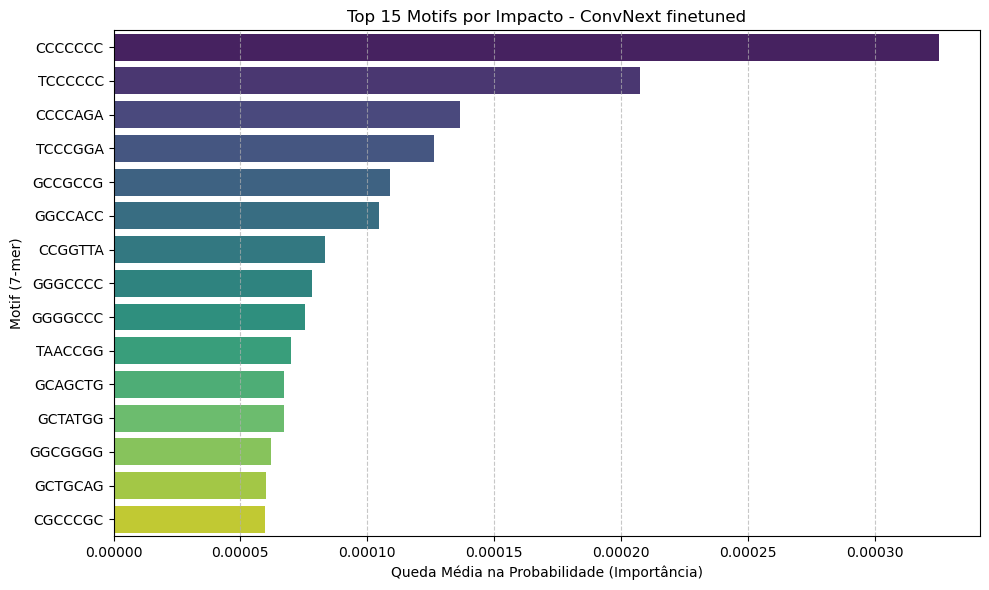

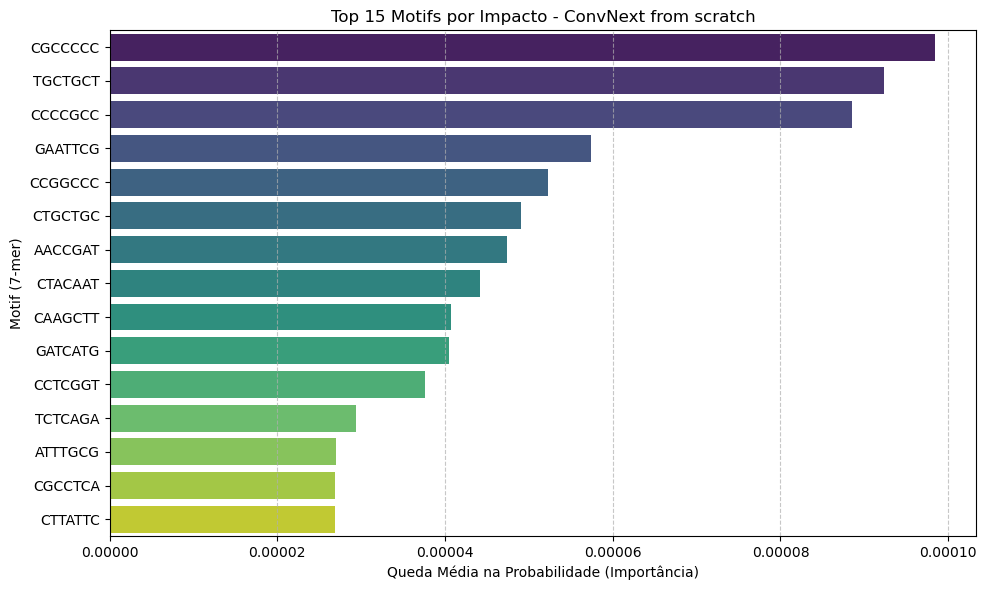

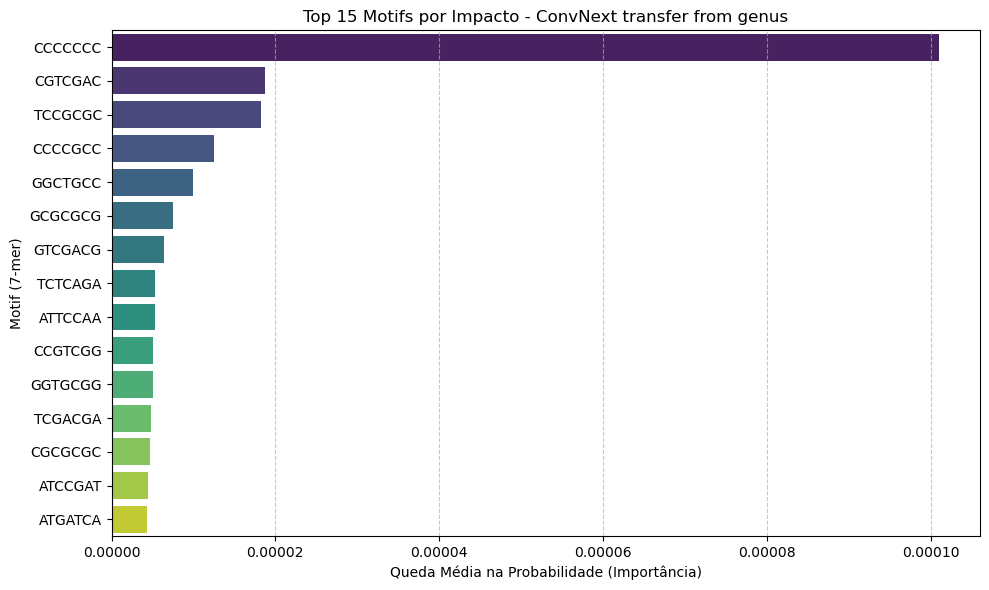

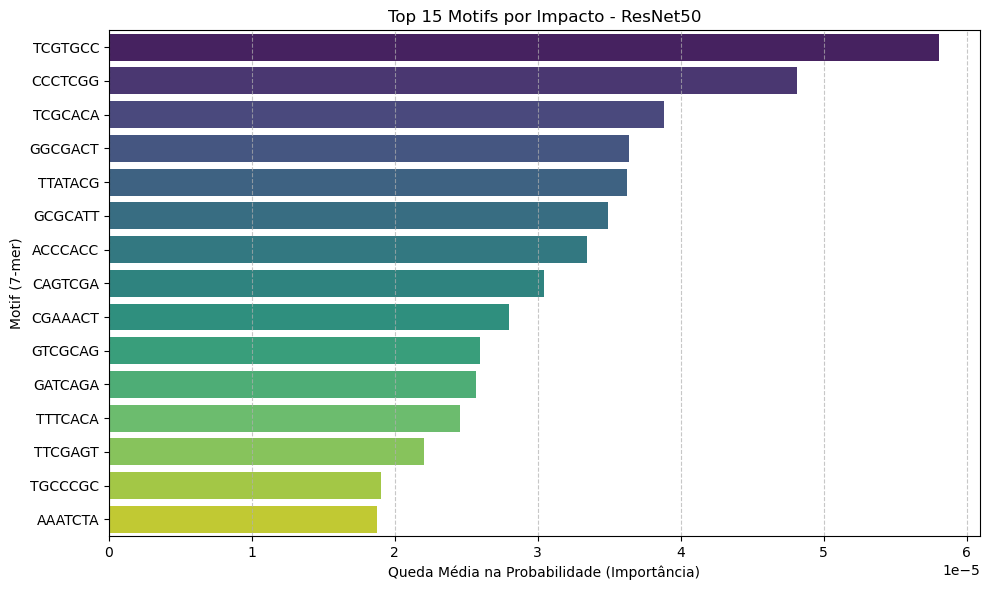

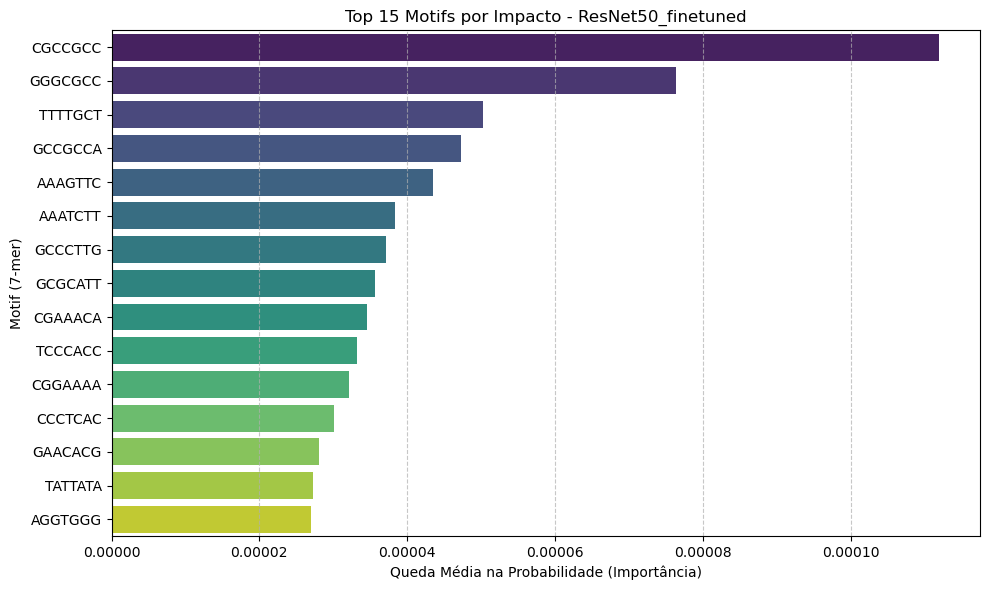

In [33]:
for model_dict in models:
    plot_top_motifs(model_dict['motiffs_rel'])

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def generate_slope_graph(df_list, model_names, title, top_n=10, min_label_dist=0.0002):
    """
    Gera um Slope Graph com ajuste automático de labels para evitar sobreposição.
    min_label_dist: Distância vertical mínima entre labels (ajuste conforme a escala do seu impacto).
    """
    plt.figure(figsize=(14, 10))
    
    # 1. Identificar motifs no Top N de qualquer um dos modelos
    all_top_motifs = set()
    for df in df_list:
        all_top_motifs.update(df.sort_values('mean_probability_drop', ascending=False).head(top_n)['motif'])
    
    all_top_motifs = sorted(list(all_top_motifs))
    x_coords = np.arange(len(model_names))
    motif_data = []

    # 2. Coletar dados e plotar as linhas principais
    for motif in all_top_motifs:
        impacts = []
        for df in df_list:
            val = df[df['motif'] == motif]['mean_probability_drop'].values
            impacts.append(val[0] if len(val) > 0 else 0)
        motif_data.append({'motif': motif, 'impacts': impacts})
        plt.plot(x_coords, impacts, marker='o', linewidth=2.5, alpha=0.6)

    # Função interna para calcular posições não sobrepostas
    def get_adjusted_y(original_y, min_dist):
        if len(original_y) == 0: return []
        idx = np.argsort(original_y)
        y_sorted = np.array(original_y)[idx]
        for i in range(1, len(y_sorted)):
            if y_sorted[i] - y_sorted[i-1] < min_dist:
                y_sorted[i] = y_sorted[i-1] + min_dist
        new_y = np.zeros_like(y_sorted)
        new_y[idx] = y_sorted
        return new_y

    # 3. Plotagem das Labels (Esquerda e Direita)
    for side_idx, side_label in zip([0, -1], ['left', 'right']):
        original_y = [d['impacts'][side_idx] for d in motif_data]
        adj_y = get_adjusted_y(original_y, min_label_dist)
        
        ha = 'right' if side_idx == 0 else 'left'
        offset = -0.08 if side_idx == 0 else 0.08
        
        for i, d in enumerate(motif_data):
            # Desenha o texto na posição ajustada
            plt.text(x_coords[side_idx] + offset, adj_y[i], d['motif'], 
                     ha=ha, va='center', fontsize=10, fontweight='bold')
            
            # Desenha linha conetora pontilhada se houve ajuste significativo
            if abs(adj_y[i] - original_y[i]) > 1e-7:
                plt.plot([x_coords[side_idx] + (offset*0.8), x_coords[side_idx]], 
                         [adj_y[i], original_y[i]], color='gray', linestyle=':', linewidth=0.8, alpha=0.5)

    # 4. Estética Final (Padrão Dissertação)
    plt.xticks(x_coords, model_names, fontsize=13, fontweight='bold')
    plt.title(title, fontsize=16, pad=30, fontweight='bold')
    plt.ylabel('Impacto (Queda na Probabilidade)', fontsize=13)
    
    # Remove moldura para um visual mais limpo
    for spine in plt.gca().spines.values():
        spine.set_visible(False)
        
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- Exemplo de Uso ---
# generate_improved_slope_graph([df_scratch, df_transfer, df_fine], 
#                               ['Scratch', 'Transfer Genus', 'Finetuned'],
#                               'Evolução da Importância de Motifs - ConvNext',
#                               min_label_dist=0.0003)

In [35]:
results_convnext = []
names_convnext = []

results_resnet = []
names_resnet = []

for model_dict in models:
    if model_dict['model_name'].lower().startswith("convnext"):
        names_convnext.append(model_dict['model_name'])
        results_convnext.append(model_dict['motiffs_rel'])
    elif model_dict['model_name'].lower().startswith("resnet"):
        names_resnet.append(model_dict['model_name'])
        results_resnet.append(model_dict['motiffs_rel'])

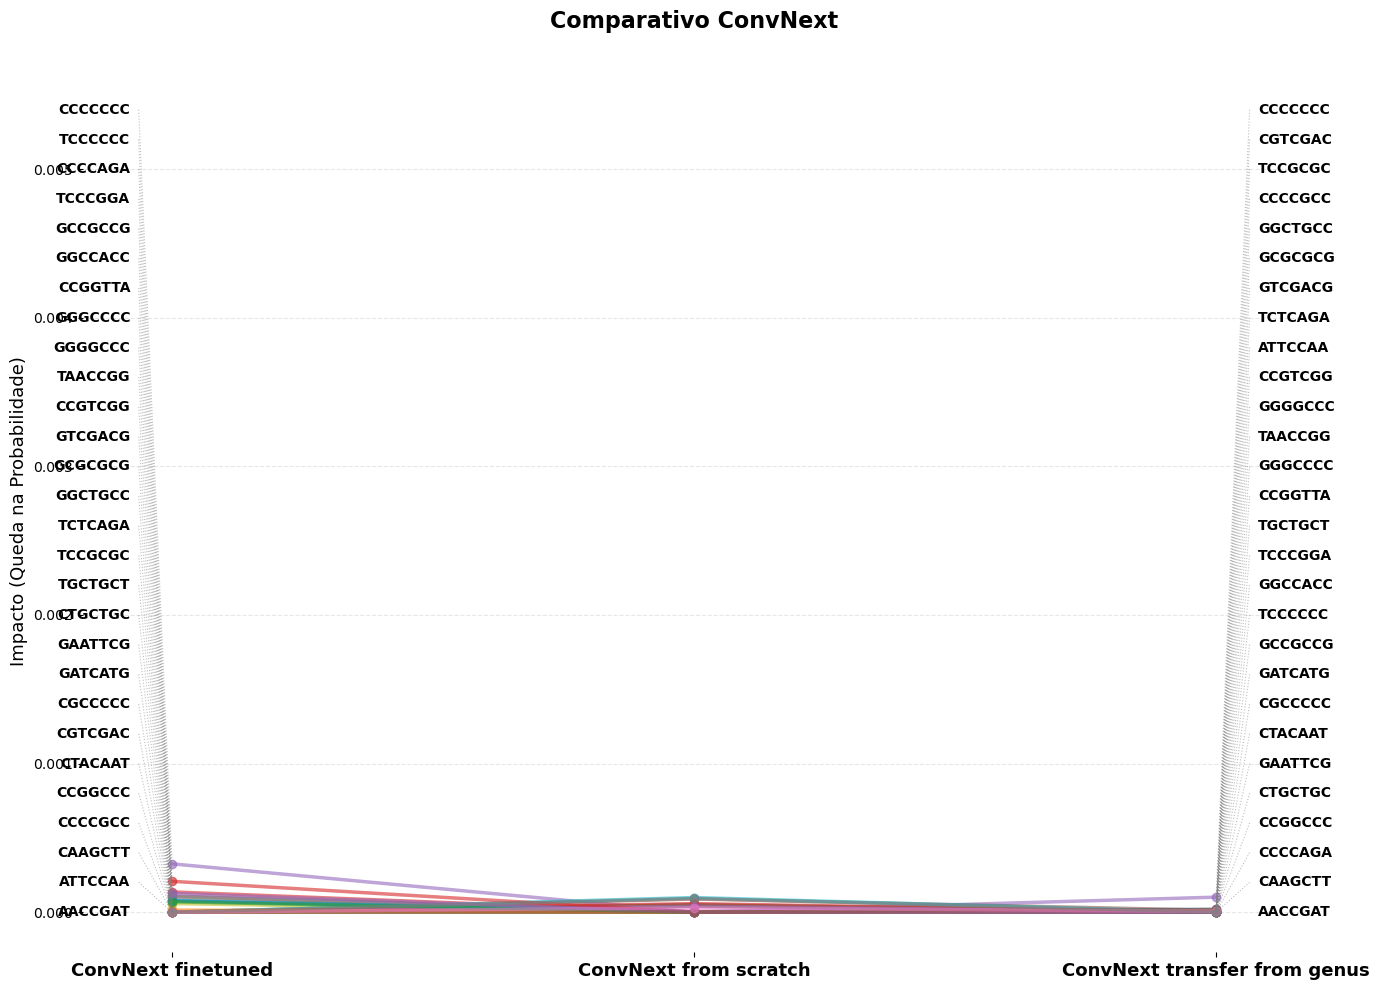

In [40]:
generate_slope_graph(results_convnext, 
                     names_convnext,
                     'Comparativo ConvNext')

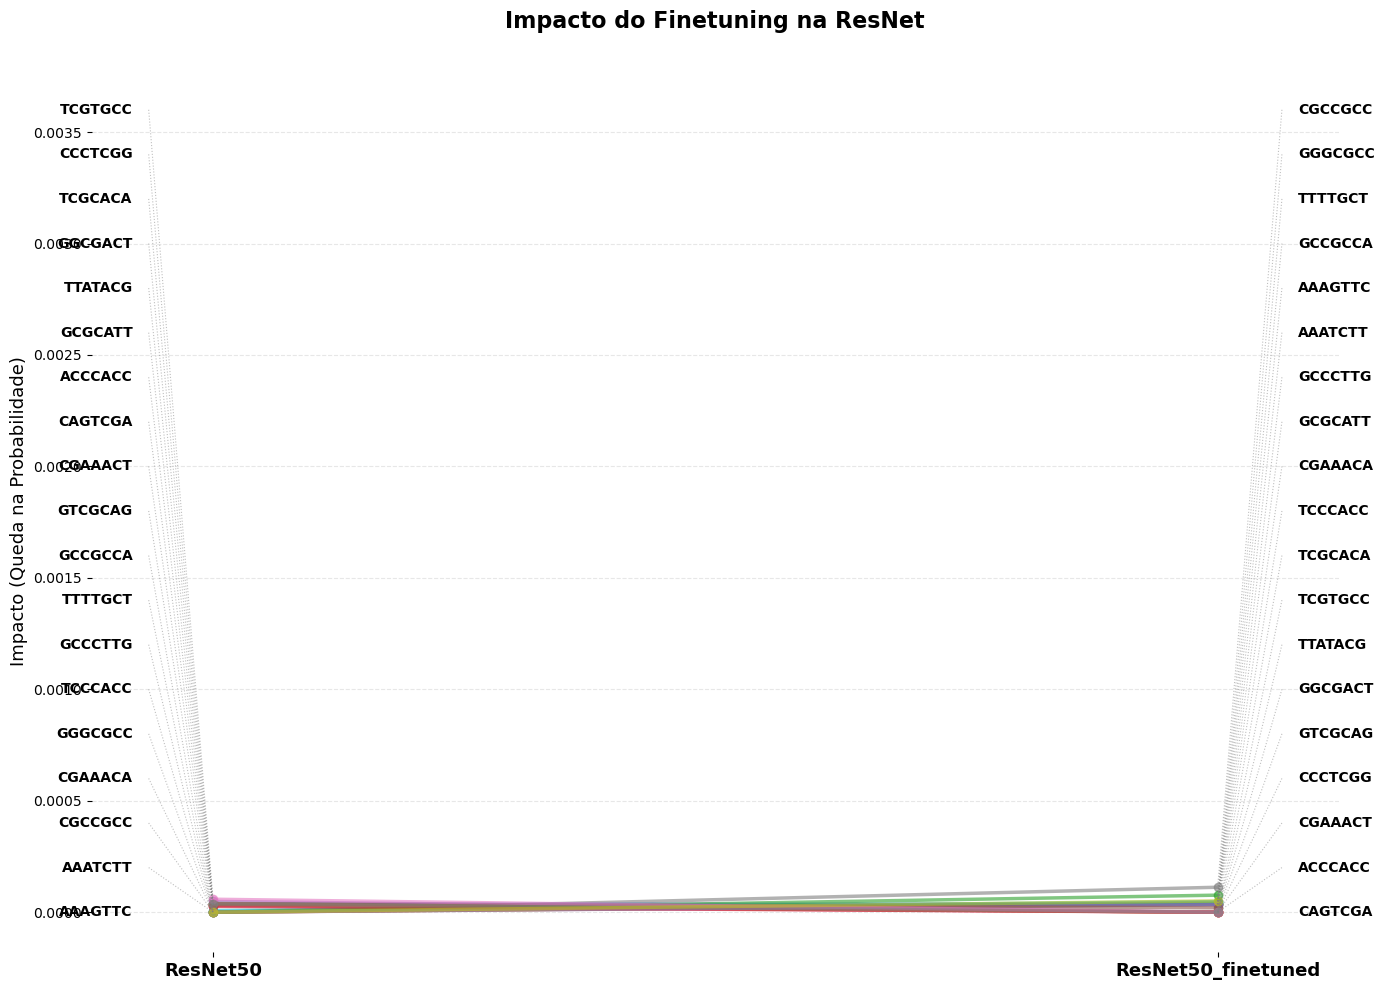

In [41]:
generate_slope_graph(results_resnet, 
                     names_resnet,
                     'Impacto do Finetuning na ResNet')

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Função para calcular Conteúdo GC (%)
def calculate_gc(seq):
    return (seq.count('G') + seq.count('C')) / len(seq) * 100

# 2. Categorização (Binning)
def bin_gc(gc):
    if gc <= 30: return 'Baixo GC (0-30%)'
    if gc <= 60: return 'Médio GC (30-60%)'
    return 'Alto GC (60-100%)'

def generate_gc_graph(df):
    # 3. Processamento
    df['gc_content'] = df['motif'].apply(calculate_gc)
    df['gc_range'] = df['gc_content'].apply(bin_gc)
    
    # 4. Plotagem
    plt.figure(figsize=(10, 7))
    sns.violinplot(data=df, x='gc_range', y='mean_probability_drop', 
                   palette='muted', inner='point',
                   order=['Baixo GC (0-30%)', 'Médio GC (30-60%)', 'Alto GC (60-100%)'])
    
    plt.title(f'Distribuição do Impacto por Conteúdo GC - {df['model_name']}')
    plt.xlabel('Faixa de Conteúdo GC (%)')
    plt.ylabel('Impacto (Queda na Probabilidade)')
    plt.savefig('violin_impact_vs_gc.png')

/tmp/ipykernel_53130/353724130.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='gc_range', y='mean_probability_drop',
/tmp/ipykernel_53130/353724130.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='gc_range', y='mean_probability_drop',
/tmp/ipykernel_53130/353724130.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='gc_range', y='mean_probability_drop',
/tmp/ipykernel_53130/353724130.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0

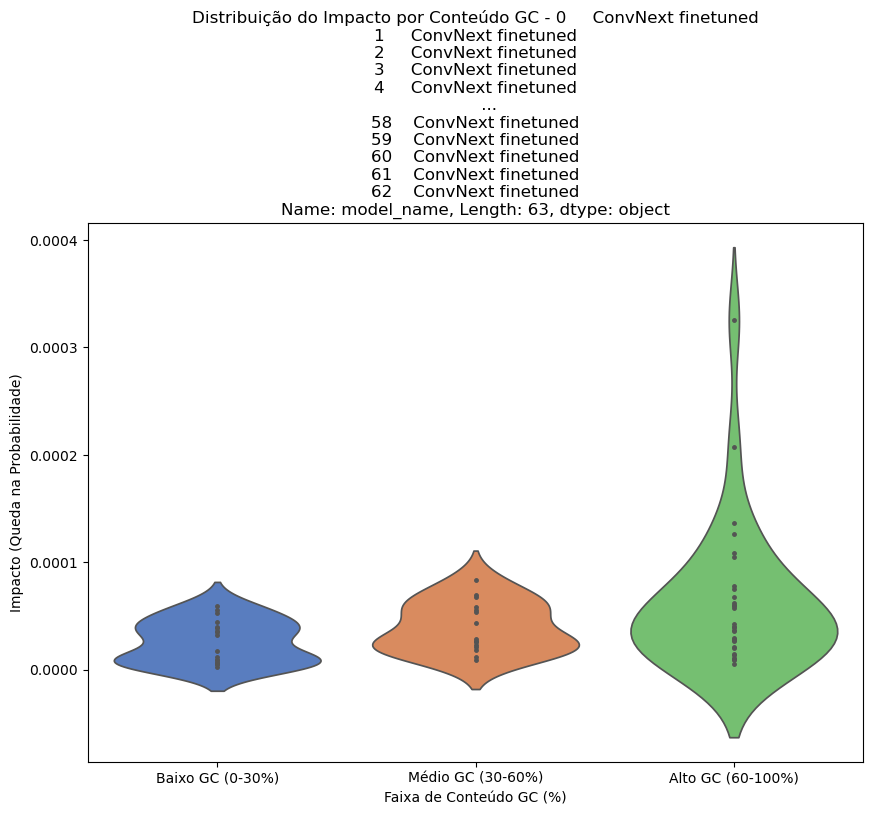

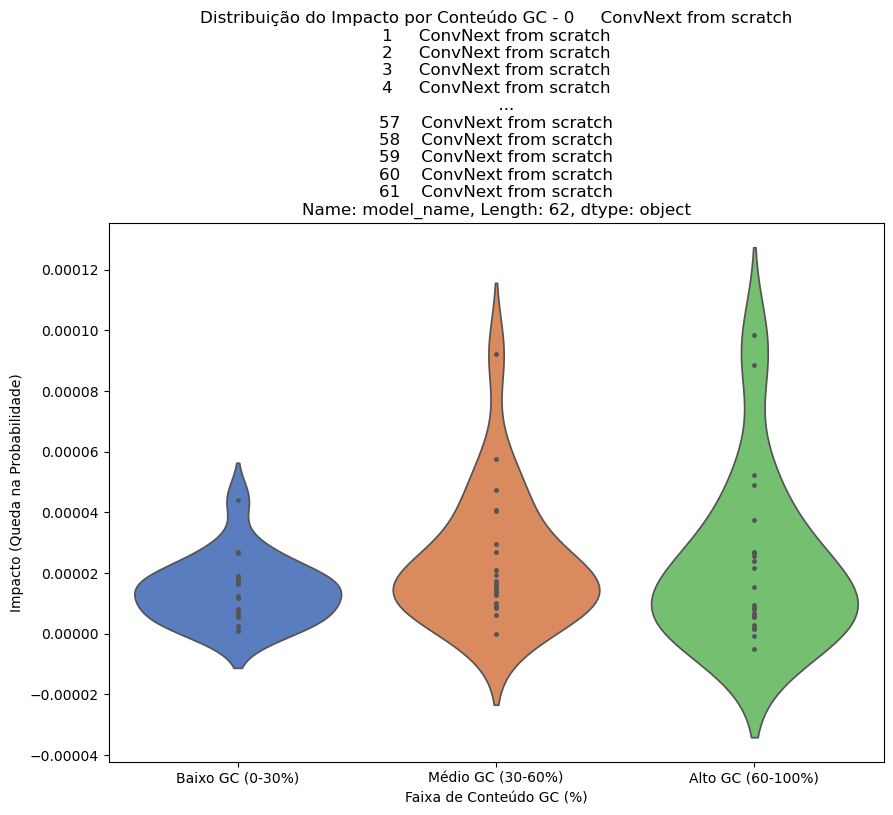

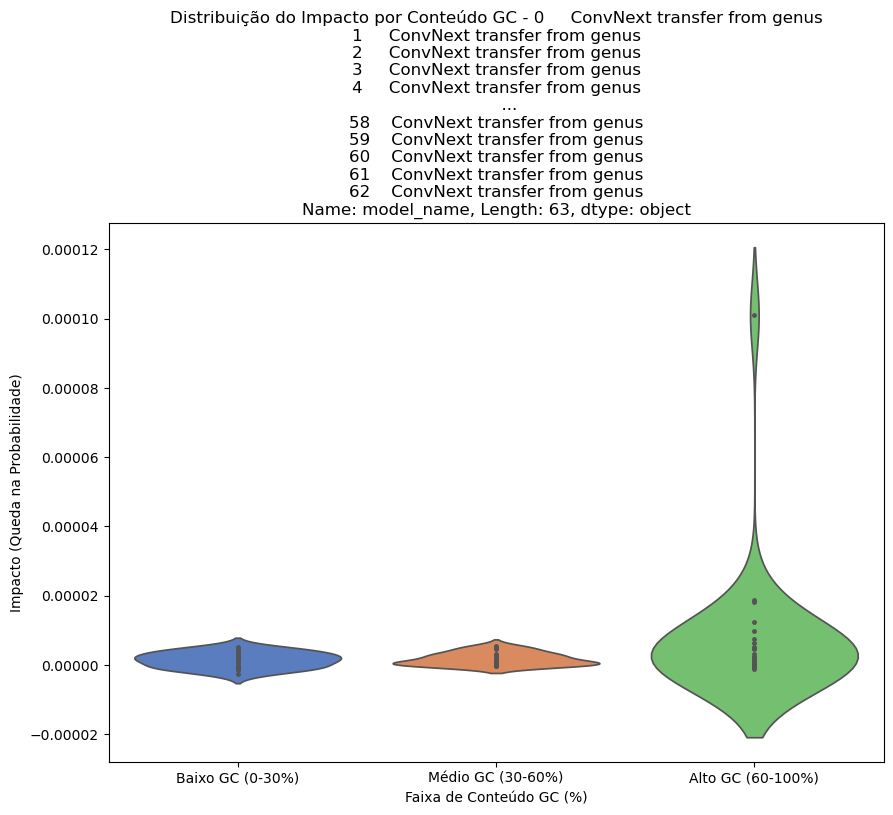

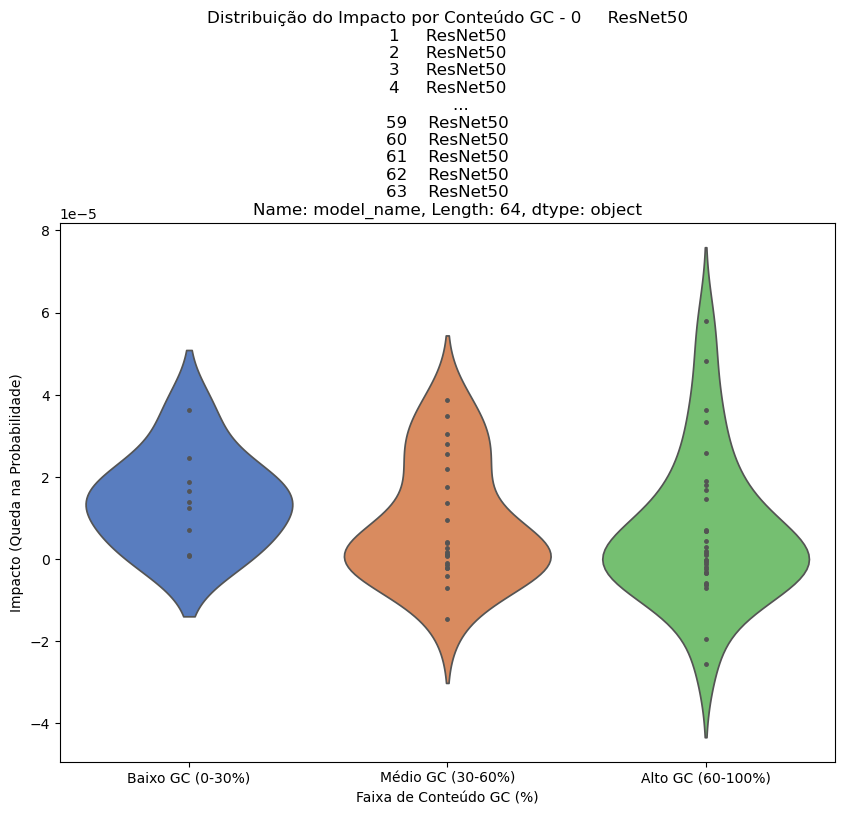

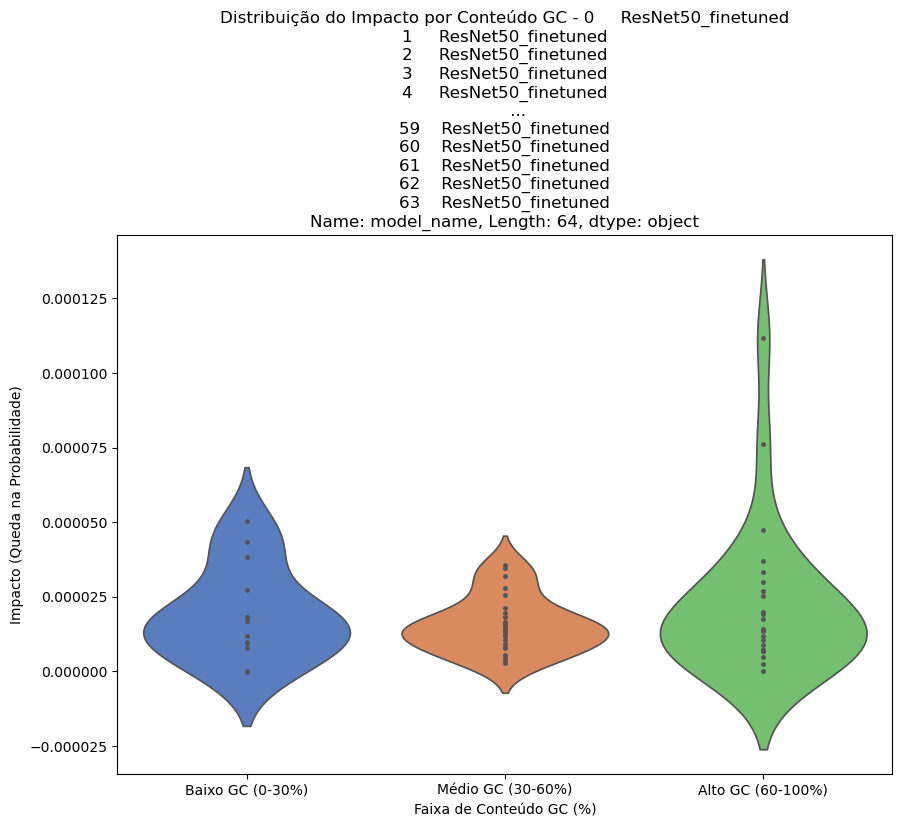

In [37]:
for model_dict in models:
    generate_gc_graph(model_dict['motiffs_rel'])

In [42]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from tqdm import tqdm

def fast_motif_cooccurrence_long_reads(df, motifs_list, window_size=512, stride=256, device='cuda'):
    """
    Busca rápida de co-ocorrência em Long Reads usando um DataFrame.
    A co-ocorrência é definida pela presença de dois motifs na mesma leitura longa.
    """
    num_motifs = len(motifs_list)
    K = len(motifs_list[0])
    
    # 1. Preparação dos Kernels (Motifs)
    motif_kernels = torch.zeros((num_motifs, 4, K), device=device)
    base_to_idx = {'A': 0, 'C': 1, 'G': 2, 'T': 3}
    for i, m in enumerate(motifs_list):
        for pos, base in enumerate(m):
            if base in base_to_idx:
                motif_kernels[i, base_to_idx[base], pos] = 1.0

    # Inicializa matrizes na GPU
    interaction_matrix = torch.zeros((num_motifs, num_motifs), device=device)
    occurrence_counts = torch.zeros(num_motifs, device=device)

    with torch.no_grad():
        # Iteramos pelas Long Reads no DataFrame
        for _, row in tqdm(df.iterrows(), total=len(df), desc="Escaneando Long Reads"):
            # A. Fatiamento em Janelas
            # Usando a função text_to_tensor já definida anteriormente
            windows_tensor = text_to_tensor(row['sequence'], window_size, stride)
            if windows_tensor is None: continue
            
            windows_tensor = windows_tensor.to(device) # Shape: (N_janelas, 512)

            # B. One-Hot Encoding das Janelas
            search_oh = torch.zeros((*windows_tensor.shape, 4), device=device)
            valid_mask = (windows_tensor >= 0) & (windows_tensor < 4)
            search_oh[valid_mask] = F.one_hot(windows_tensor[valid_mask], num_classes=4).float()
            search_oh = search_oh.permute(0, 2, 1) # (N_janelas, 4, 512)
            
            # C. Busca via Convolução
            search_results = F.conv1d(search_oh, motif_kernels) # (N_janelas, N_motifs, L-K+1)
            
            # D. Presença na Long Read: 
            # Verificamos se o motif apareceu em QUALQUER janela da leitura
            # presence shape: (1, Num_Motifs)
            presence = (search_results == K).any(dim=-1).any(dim=0).float().unsqueeze(0)
            
            # E. Atualiza Matrizes
            interaction_matrix += torch.matmul(presence.T, presence)
            occurrence_counts += presence.squeeze(0)

    # 2. Normalização (Índice de Jaccard)
    counts_i = occurrence_counts.view(-1, 1)
    counts_j = occurrence_counts.view(1, -1)
    union_matrix = counts_i + counts_j - interaction_matrix
    jaccard_matrix = interaction_matrix / torch.clamp(union_matrix, min=1.0)
    
    return jaccard_matrix.cpu().numpy(), motifs_list

In [45]:
for model_dict in models:
    print(f"rodando para: {model_dict['model_name']}")
    model_dict['jaccard_matrix'] = fast_motif_cooccurrence_long_reads(sample_dataset,model_dict['motiffs_rel']['motif'])

rodando para: ConvNext finetuned


Escaneando Long Reads: 100%|██████████| 43503/43503 [01:55<00:00, 377.85it/s]


rodando para: ConvNext from scratch


Escaneando Long Reads: 100%|██████████| 43503/43503 [01:55<00:00, 378.10it/s]


rodando para: ConvNext transfer from genus


Escaneando Long Reads: 100%|██████████| 43503/43503 [01:50<00:00, 394.67it/s]


rodando para: ResNet50


Escaneando Long Reads: 100%|██████████| 43503/43503 [01:55<00:00, 376.94it/s]


rodando para: ResNet50_finetuned


Escaneando Long Reads: 100%|██████████| 43503/43503 [01:56<00:00, 374.12it/s]


In [46]:
for model_dict in models:
    nomes = model_dict['jaccard_matrix'][1]
    df_jaccard = pd.DataFrame(model_dict['jaccard_matrix'][0], index=nomes, columns=nomes)
    df_jaccard.to_parquet(f'results_motifs/motif_interaction_jaccard_{model_dict['model_name'].lower().replace(" ","_")}.parquet')

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LogNorm

def plot_motif_clustermap(jaccard_matrix, motif_names, model_name, output_name="clustermap.png"):
    # 1. Preparar o DataFrame
    df = pd.DataFrame(jaccard_matrix, index=motif_names, columns=motif_names)
    
    # 2. Configurar o estilo "Paper"
    sns.set_theme(style="white")
    
    # 3. Gerar o Clustermap
    # cmap: 'mako', 'rocket' ou 'YlGnBu' são ótimas para bioinformática
    g = sns.clustermap(
        df, 
        method='ward',      # Método de agrupamento (Ward minimiza a variância)
        #cmap="mako",        # Paleta de cores escura e profissional
        linewidths=.5, 
        figsize=(12, 12),
        cbar_kws={'label': 'Índice de Jaccard (Co-ocorrência)'},
        annot=False,         # Defina como True se tiver poucos motivos (ex: < 15)
        norm=LogNorm(vmin=0.001, vmax=1), # Valores abaixo de 0.001 ficam pretos, o resto escala logaritmicamente
        cmap="magma",
    )
    
    # Ajustar títulos e labels
    g.fig.suptitle(f'Módulos de Motifs: Interação via Índice de Jaccard\nModelo: {model_name}', 
                   fontsize=16, fontweight='bold', y=1.02)
    
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right')
    
    # 4. Salvar
    plt.savefig(output_name, dpi=300, bbox_inches='tight')
    plt.show()

# --- Exemplo de Uso ---
# plot_motif_clustermap(matriz_jaccard, nomes, "ConvNext finetuned")

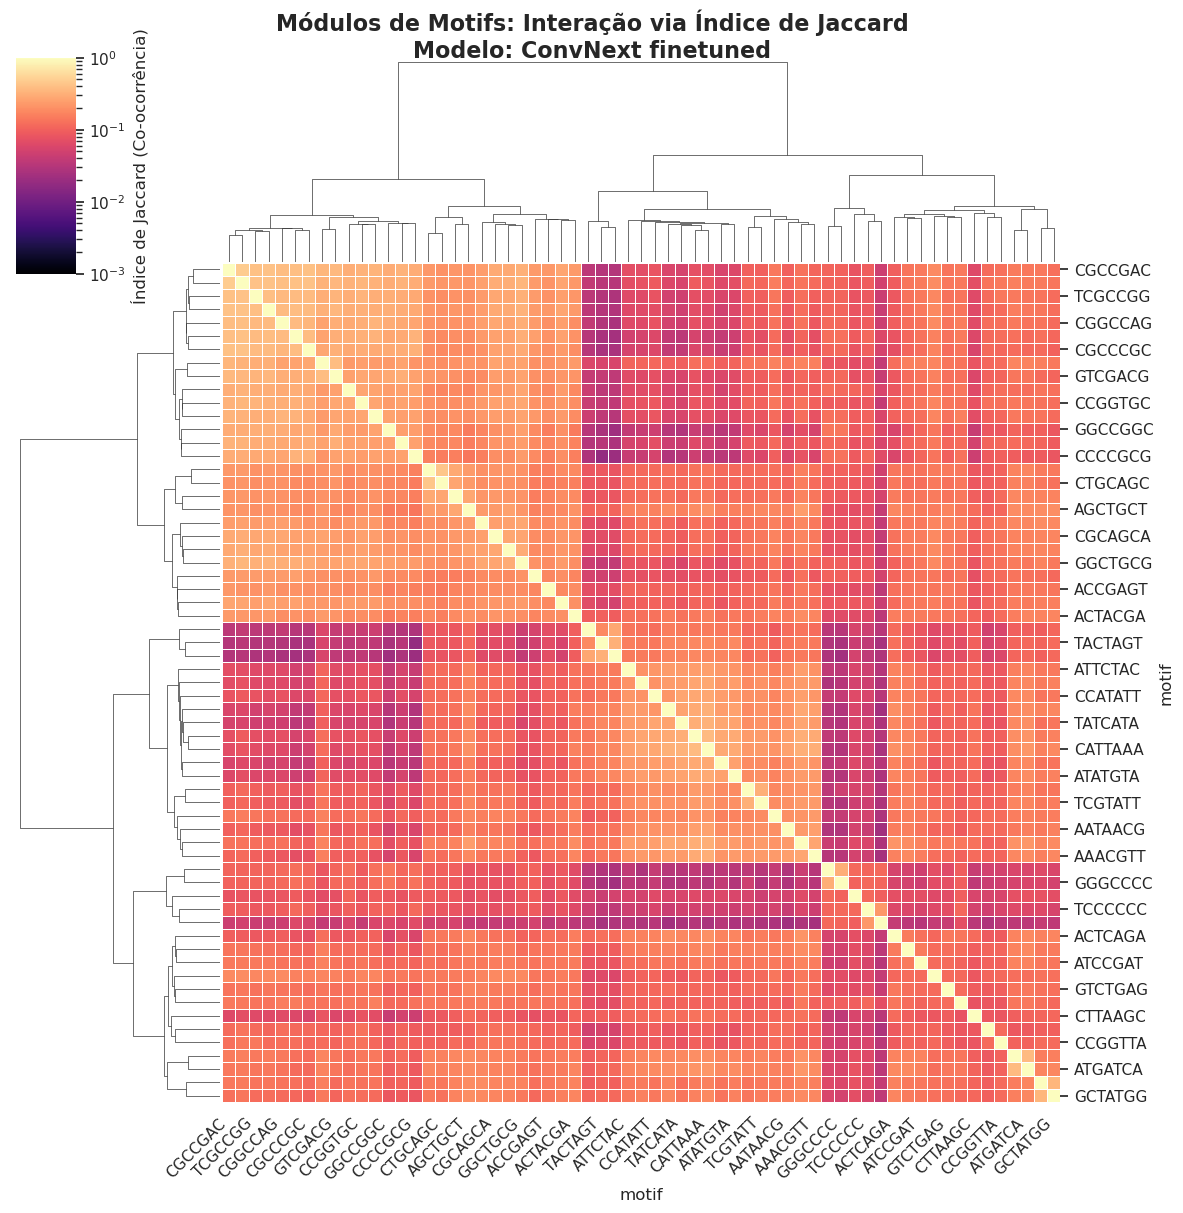

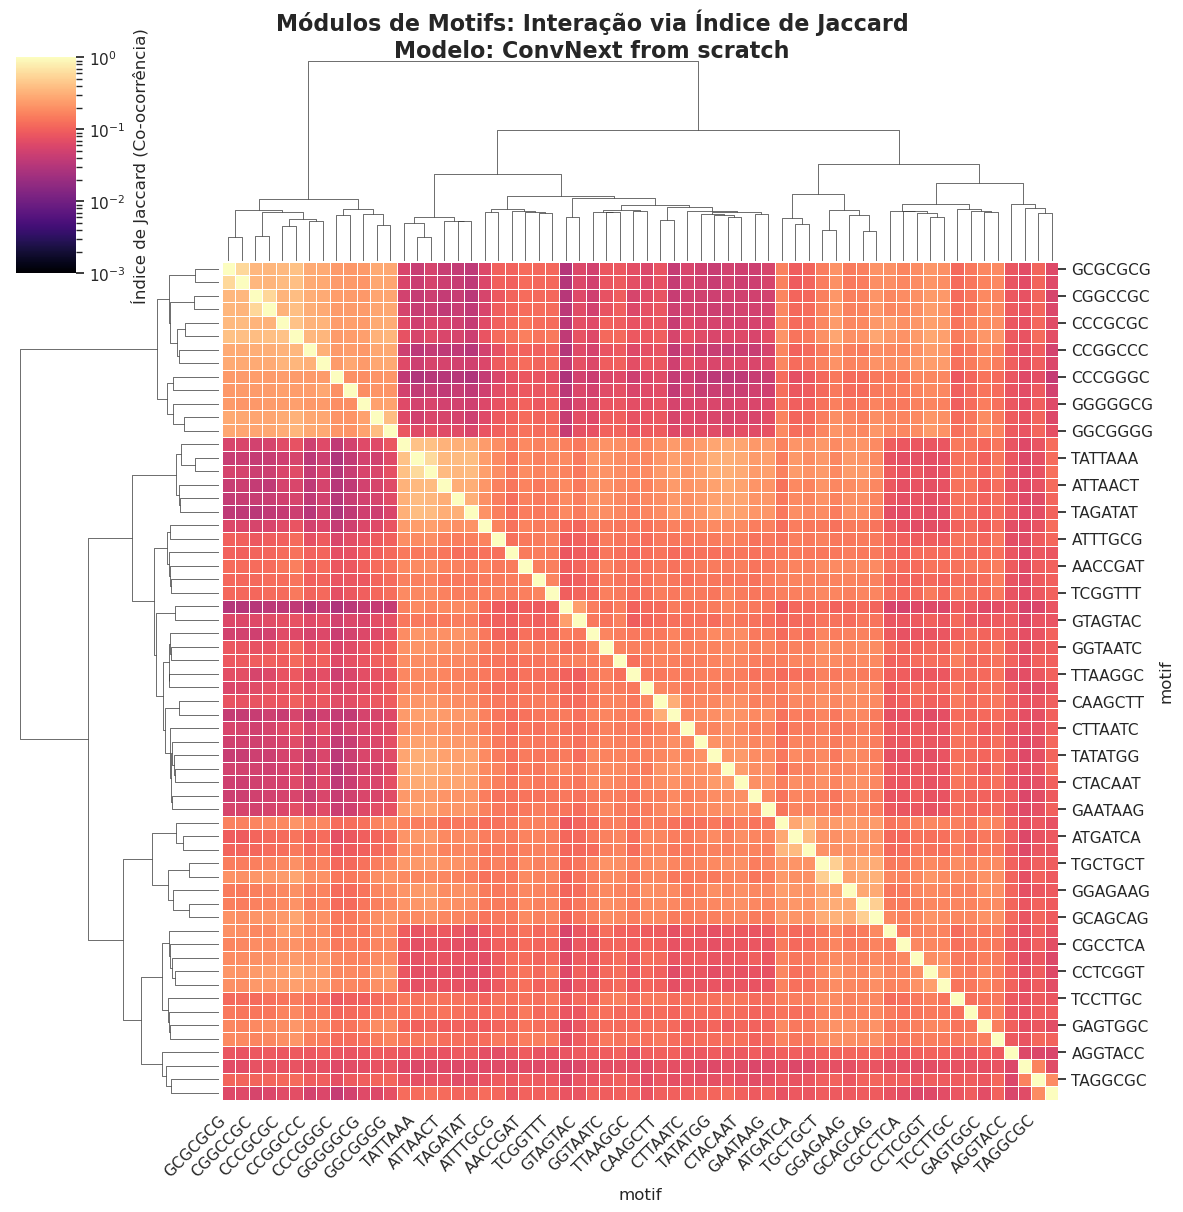

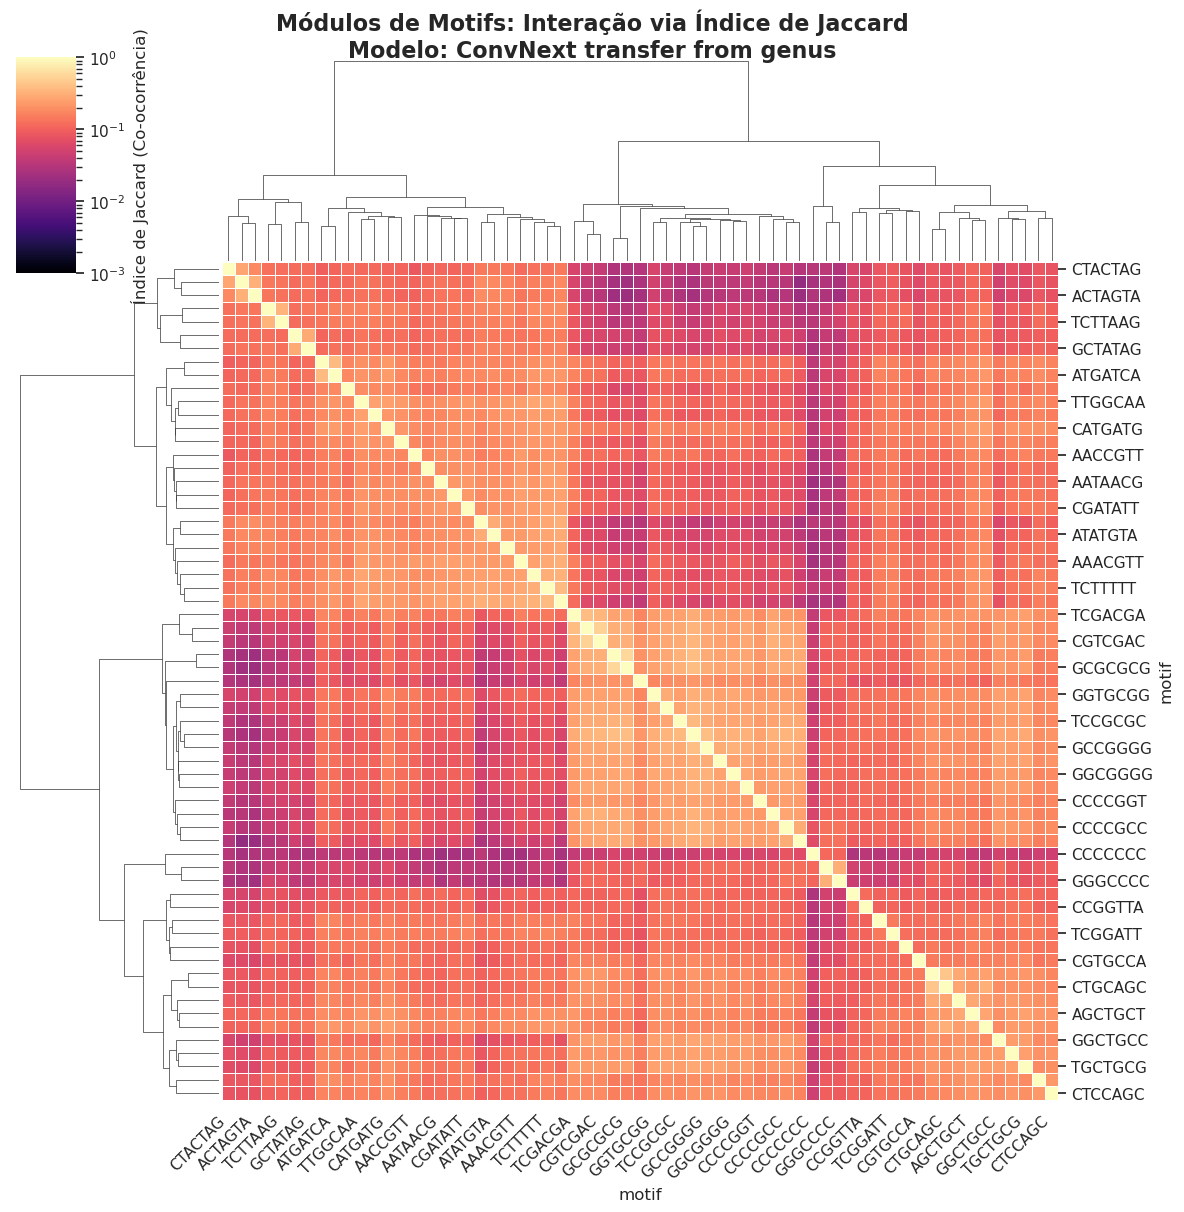

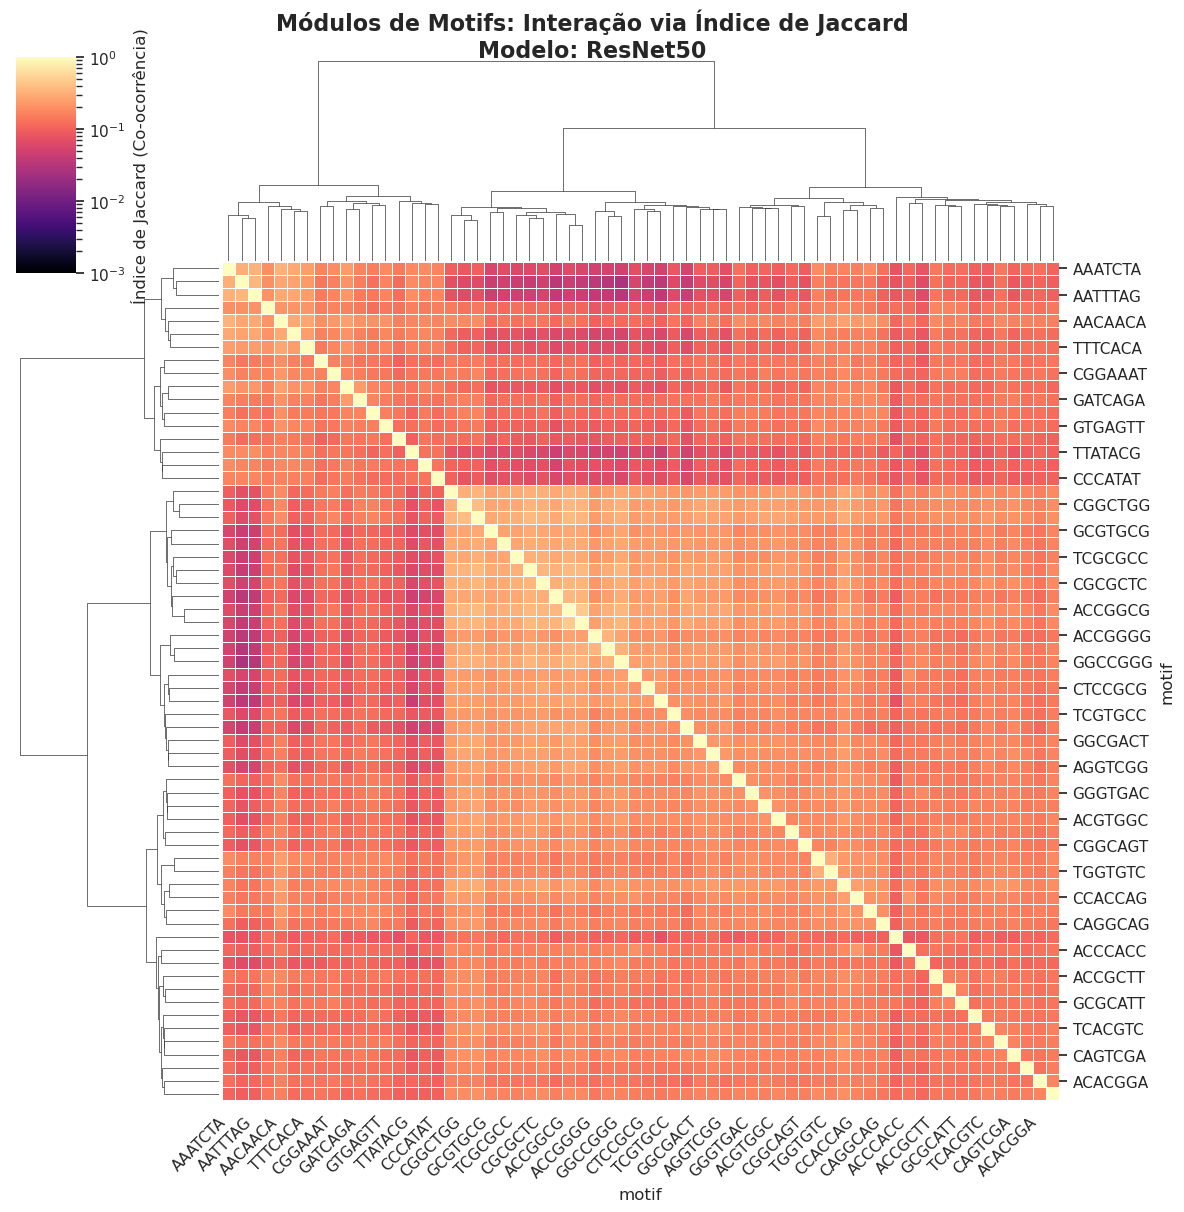

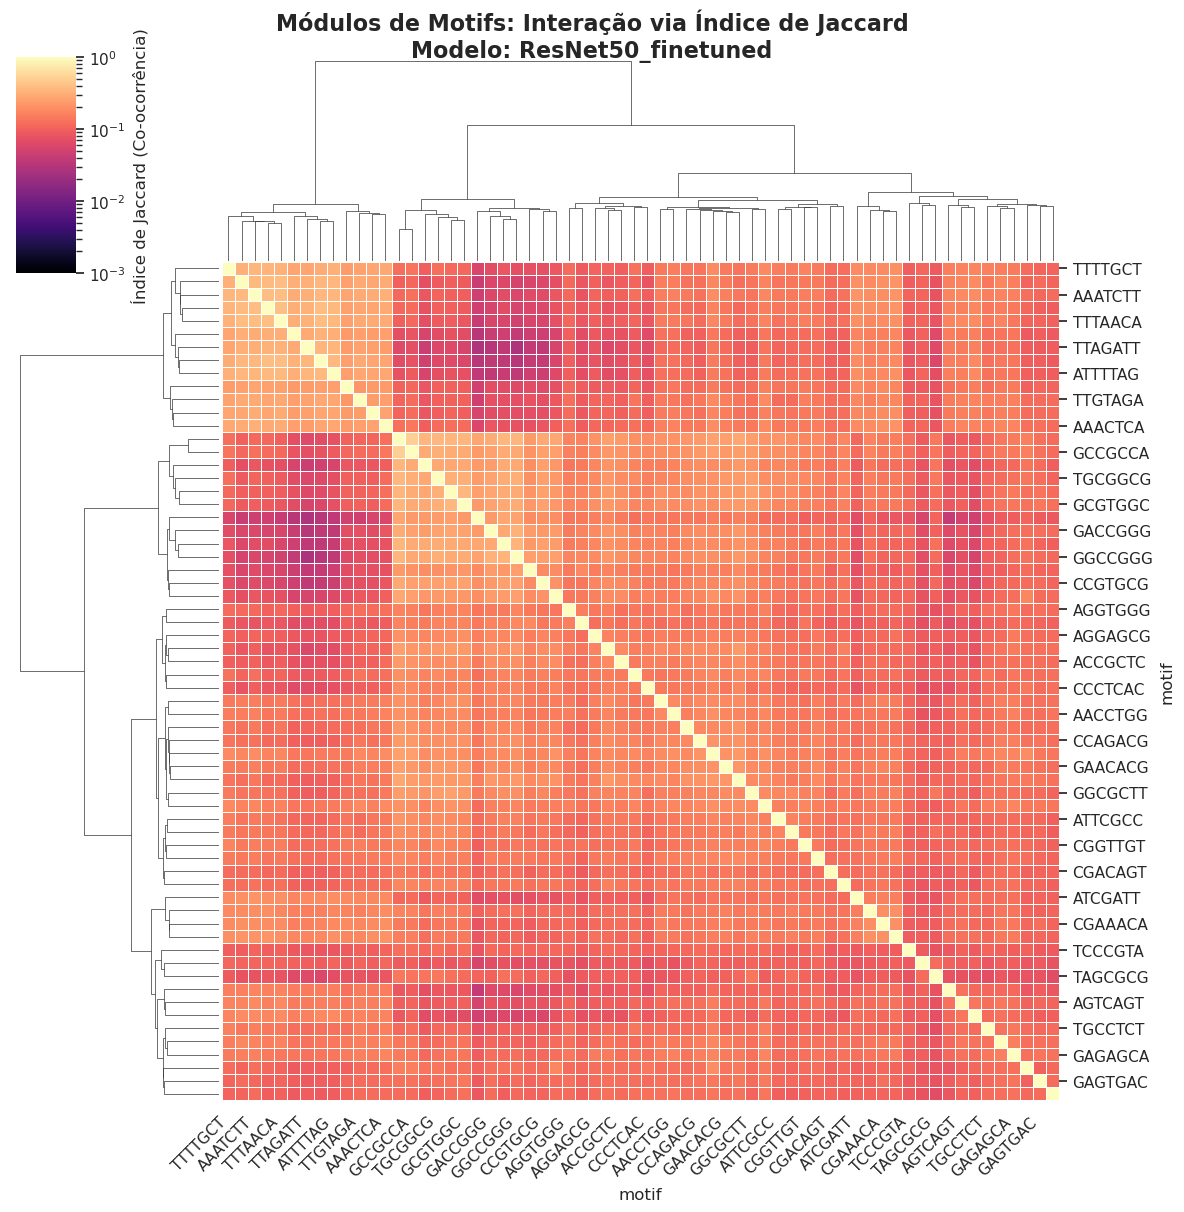

In [48]:
for model_dict in models:
    motif_names = model_dict['jaccard_matrix'][1]
    jaccard_matrix = model_dict['jaccard_matrix'][0]
    plot_motif_clustermap(jaccard_matrix, motif_names, model_dict['model_name'], output_name=f"clustermap_{model_dict["model_name"].lower().replace(" ","_")}.png")